# Chapter 7: Symmetric Matrices, Quadratic Forms & Spectral Methods — Interactive Coding Project

Welcome to the companion coding notebook for **Chapter 7 (Symmetric Matrices)** of *Mathematics for AI* (`math4ai.org`).

In this notebook, we verify every analytical derivation from **Exercises 1–11** in `chapter7-symmetric-matrix/exercises/math.md` and visualize the geometry of symmetric matrices across modern AI pipelines:
- **Part I — Spectral Theorem, Gram Kernels & Cholesky Decomposition (Exercises 1–5)**:
  - Orthogonal diagonalization $A = Q\Lambda Q^\top$ and outer-product spectral sum $\sum_i \lambda_i \mathbf{q}_i\mathbf{q}_i^\top$ (Exercise 1)
  - Linear Gram kernel $K = \Phi^\top \Phi$ and feature-norm energy $\mathbf{x}^\top K\mathbf{x} = \|\Phi\mathbf{x}\|_2^2$ (Exercise 2)
  - Sylvester's criterion, Cholesky factorization $\Sigma = LL^\top$, Gaussian sampling $\mathbf{x} = L\mathbf{z}$, and precision matrix $\Sigma^{-1}$ (Exercise 3)
  - Principal Component Analysis (PCA) cumulative variance threshold and projection energy bound (Exercise 4)
  - Kronecker structure of the 2D RBF kernel $K = K_{1\text{D}} \otimes K_{1\text{D}}$ on unit-square corners (Exercise 5)
- **Part II — AI Applications: GPTQ, Newton Optimization, Mahalanobis, Recommender Gram, Graph Laplacian & Rayleigh Quotient (Exercises 6–11)**:
  - Layer-wise LLM quantization (GPTQ) Hessian loss $\mathbf{e}^\top H\mathbf{e}$ and minimum-error unit direction $\mathbf{e}^* = \mathbf{q}_{\min}$ (Exercise 6)
  - Quadratic optimization surface, exact Newton step $\Delta\mathbf{w} = -H^{-1}\mathbf{g}$, and eigenbasis decoupling (Exercise 7)
  - Mahalanobis distance $d_M(\mathbf{x}) = \|L^{-1}(\mathbf{x}-\boldsymbol{\mu})\|_2$ and $\tau=3$ anomaly boundary (Exercise 8)
  - Recommender dual Gram matrices $G_c = R^\top R$ and $G_r = RR^\top$ shared nonzero spectrum (Exercise 9)
  - Graph Laplacian $L = D - A$ quadratic energy, algebraic connectivity $\lambda_1$, and Fiedler vector partitioning (Exercise 10)
  - Rayleigh quotient $R(\mathbf{x}) = \frac{\mathbf{x}^\top A\mathbf{x}}{\mathbf{x}^\top \mathbf{x}}$ polar geometry $R(\theta) = 1.5 + 0.5\sin(2\theta)$ (Exercise 11)


In [1]:
import numpy as np
import scipy.linalg as la
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})
print("Environment initialized successfully.")


Environment initialized successfully.


---
## Exercise 1: Spectral Decomposition of a $3 \times 3$ Symmetric Matrix

Given the real symmetric matrix:
$$A = \begin{bmatrix} 5 & 2 & -1 \\ 2 & 0 & 2 \\ -1 & 2 & 5 \end{bmatrix}$$

1. **Symmetry & Trace/Determinant**: $A^\top = A$, $\operatorname{tr}(A) = 10$, $\det(A) = -48$.
2. **Eigenvalues**: Exploiting reflection symmetry $(1, 0, -1)^\top \implies \lambda_2 = 6$, and the $2\times 2$ block on $\operatorname{span}\{(1,0,1)^\top, (0,1,0)^\top\}$ yields $\lambda^2 - 4\lambda - 8 = 0 \implies \lambda_0 = 2 - 2\sqrt{3} \approx -1.4641$, $\lambda_1 = 2 + 2\sqrt{3} \approx 5.4641$.
3. **Rank-1 Spectral Sum**: Notice how the $\sqrt{3}$ cross-terms cancel cleanly in $\lambda_0\mathbf{q}_0\mathbf{q}_0^\top + \lambda_1\mathbf{q}_1\mathbf{q}_1^\top = \begin{bmatrix} 2 & 2 & 2 \\ 2 & 0 & 2 \\ 2 & 2 & 2 \end{bmatrix}$, and adding $\lambda_2\mathbf{q}_2\mathbf{q}_2^\top = \begin{bmatrix} 3 & 0 & -3 \\ 0 & 0 & 0 \\ -3 & 0 & 3 \end{bmatrix}$ reconstructs $A$ exactly.


In [2]:
A_ex1 = np.array([[5, 2, -1],
                  [2, 0,  2],
                  [-1, 2, 5]], dtype=float)

eigvals_1, Q_1 = np.linalg.eigh(A_ex1)
exact_eigvals_1 = np.array([2 - 2 * np.sqrt(3), 2 + 2 * np.sqrt(3), 6.0])

print("Task 1 - Is symmetric:", np.allclose(A_ex1, A_ex1.T))
print("Task 2 - Eigenvalues (eigh):", eigvals_1)
print("Task 2 - Exact eigenvalues :", exact_eigvals_1)
print("Task 3 - Orthonormality ||Q^T Q - I||_F:", f"{np.linalg.norm(Q_1.T @ Q_1 - np.eye(3)):.2e}")

P0 = eigvals_1[0] * np.outer(Q_1[:, 0], Q_1[:, 0])
P1 = eigvals_1[1] * np.outer(Q_1[:, 1], Q_1[:, 1])
P2 = eigvals_1[2] * np.outer(Q_1[:, 2], Q_1[:, 2])

print("\nTask 5 - Partial sum (lambda_0 q_0 q_0^T + lambda_1 q_1 q_1^T):")
print(P0 + P1)
print("Task 5 - Rank-1 term (lambda_2 q_2 q_2^T):")
print(P2)
print("Task 5 - Full spectral reconstruction error ||A - sum_i lambda_i q_i q_i^T||_F:",
      f"{np.linalg.norm(A_ex1 - (P0 + P1 + P2)):.2e}")


Task 1 - Is symmetric: True
Task 2 - Eigenvalues (eigh): [-1.4641  5.4641  6.    ]
Task 2 - Exact eigenvalues : [-1.4641  5.4641  6.    ]
Task 3 - Orthonormality ||Q^T Q - I||_F: 9.47e-16

Task 5 - Partial sum (lambda_0 q_0 q_0^T + lambda_1 q_1 q_1^T):
[[2. 2. 2.]
 [2. 0. 2.]
 [2. 2. 2.]]
Task 5 - Rank-1 term (lambda_2 q_2 q_2^T):
[[ 3.  0. -3.]
 [ 0.  0. -0.]
 [-3. -0.  3.]]
Task 5 - Full spectral reconstruction error ||A - sum_i lambda_i q_i q_i^T||_F: 4.90e-15


---
## Exercise 2: Linear Kernel Matrix $K = \Phi^\top \Phi$ and PSD Verification

Given the feature matrix $\Phi \in \mathbb{R}^{2 \times 3}$ whose columns are $\boldsymbol{\phi}_1 = [1, 2]^\top, \boldsymbol{\phi}_2 = [2, 1]^\top, \boldsymbol{\phi}_3 = [1, 1]^\top$:
$$\Phi = \begin{bmatrix} 1 & 2 & 1 \\ 2 & 1 & 1 \end{bmatrix}, \qquad K = \Phi^\top \Phi = \begin{bmatrix} 5 & 4 & 3 \\ 4 & 5 & 3 \\ 3 & 3 & 2 \end{bmatrix}$$

- Since $\operatorname{rank}(\Phi) = 2 < 3$, $K$ is **positive semi-definite (PSD)** with one zero eigenvalue $\lambda_0 = 0$ and two positive eigenvalues $\lambda_{1,2} = 6 \mp \sqrt{34}$.
- For $\mathbf{x} = [1, -1, 1]^\top$, $\mathbf{x}^\top K\mathbf{x} = \|\Phi\mathbf{x}\|_2^2 = \|[0, 2]^\top\|_2^2 = 4$.


In [3]:
Phi = np.array([[1, 2, 1],
                [2, 1, 1]], dtype=float)
K_ex2 = Phi.T @ Phi
eigvals_2 = np.linalg.eigvalsh(K_ex2)
exact_eigvals_2 = np.array([0.0, 6.0 - np.sqrt(34), 6.0 + np.sqrt(34)])

x_ex2 = np.array([1.0, -1.0, 1.0])
quad_form = x_ex2 @ K_ex2 @ x_ex2
feat_norm_sq = np.linalg.norm(Phi @ x_ex2) ** 2

print("Task 1 - Gram Matrix K = Phi^T Phi:\n", K_ex2)
print("Task 2 - Eigenvalues of K:", eigvals_2)
print("Task 2 - Exact [0, 6-sqrt(34), 6+sqrt(34)]:", exact_eigvals_2)
print(f"Task 5 - x^T K x = {quad_form:.4f}, ||Phi x||_2^2 = {feat_norm_sq:.4f}")


Task 1 - Gram Matrix K = Phi^T Phi:
 [[5. 4. 3.]
 [4. 5. 3.]
 [3. 3. 2.]]
Task 2 - Eigenvalues of K: [ 0.  1. 11.]
Task 2 - Exact [0, 6-sqrt(34), 6+sqrt(34)]: [ 0.     0.169 11.831]
Task 5 - x^T K x = 4.0000, ||Phi x||_2^2 = 4.0000


---
## Exercise 3: Cholesky Decomposition $\Sigma = LL^\top$, Gaussian Sampling & Precision Matrix

Given the $3 \times 3$ covariance matrix:
$$\Sigma = \begin{bmatrix} 9 & 3 & -3 \\ 3 & 5 & 1 \\ -3 & 1 & 6 \end{bmatrix}$$

1. **Sylvester's Criterion**: Leading principal minors are $\Delta_1 = 9 > 0$, $\Delta_2 = 36 > 0$, $\Delta_3 = \det(\Sigma) = 144 > 0 \implies \Sigma \succ 0$.
2. **Exact Cholesky Factor**:
   $$L = \begin{bmatrix} 3 & 0 & 0 \\ 1 & 2 & 0 \\ -1 & 1 & 2 \end{bmatrix}, \qquad L^{-1} = \begin{bmatrix} \frac{1}{3} & 0 & 0 \\ -\frac{1}{6} & \frac{1}{2} & 0 \\ \frac{1}{4} & -\frac{1}{4} & \frac{1}{2} \end{bmatrix}$$
3. **Generative Sampling**: Drawing $\mathbf{z} \sim \mathcal{N}(\mathbf{0}, I_3)$ and setting $\mathbf{x} = L\mathbf{z}$ yields $\operatorname{Cov}(\mathbf{x}) = L I_3 L^\top = \Sigma$ without ever forming $\Sigma^{1/2}$ via eigendecomposition.


Task 1 - Leading principal minors (Delta_1, Delta_2, Delta_3): [  9.  36. 144.]
Task 2 - Cholesky factor L:
 [[ 3.  0.  0.]
 [ 1.  2.  0.]
 [-1.  1.  2.]]
Task 5 - 144 * Sigma^{-1} via triangular solve (exact integers):
 [[ 29. -21.  18.]
 [-21.  45. -18.]
 [ 18. -18.  36.]]
Task 4 - Empirical covariance (N=20,000) Frobenius error ||Sigma_emp - Sigma||_F: 0.1099


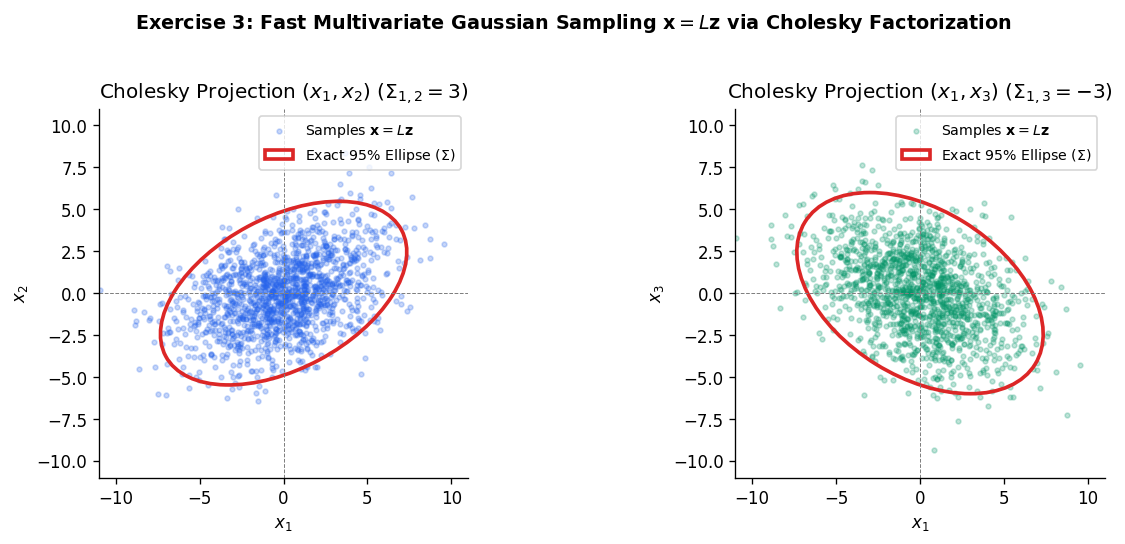

In [4]:
Sigma_ex3 = np.array([[ 9, 3, -3],
                      [ 3, 5,  1],
                      [-3, 1,  6]], dtype=float)

minors = [np.linalg.det(Sigma_ex3[:k, :k]) for k in (1, 2, 3)]
L_ex3 = np.linalg.cholesky(Sigma_ex3)
L_inv_ex3 = la.solve_triangular(L_ex3, np.eye(3), lower=True)
Sigma_inv_ex3 = L_inv_ex3.T @ L_inv_ex3

print("Task 1 - Leading principal minors (Delta_1, Delta_2, Delta_3):", np.round(minors, 4))
print("Task 2 - Cholesky factor L:\n", L_ex3)
print("Task 5 - 144 * Sigma^{-1} via triangular solve (exact integers):\n",
      np.round(144 * Sigma_inv_ex3))

# Monte Carlo verification + visualization of Cholesky Gaussian sampling
rng = np.random.default_rng(42)
N_samples = 20000
Z_samples = rng.standard_normal((3, N_samples))
X_samples = L_ex3 @ Z_samples
Sigma_emp = (X_samples @ X_samples.T) / N_samples
print("Task 4 - Empirical covariance (N=20,000) Frobenius error ||Sigma_emp - Sigma||_F:",
      f"{np.linalg.norm(Sigma_emp - Sigma_ex3):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))

for ax, (i, j), col in zip(axes, [(0, 1), (0, 2)], ["#2563eb", "#059669"]):
    ax.scatter(X_samples[i, :1500], X_samples[j, :1500], s=8, alpha=0.25, color=col, label="Samples $\\mathbf{x} = L\\mathbf{z}$")
    sub_cov = Sigma_ex3[np.ix_([i, j], [i, j])]
    vals, vecs = np.linalg.eigh(sub_cov)
    angle = np.degrees(np.arctan2(vecs[1, 1], vecs[0, 1]))
    # 95% confidence ellipse (chi2_2(0.95) approx 5.991 -> radius = sqrt(5.991) approx 2.4477)
    r95 = np.sqrt(5.991)
    ell = Ellipse((0, 0), width=2 * r95 * np.sqrt(vals[1]), height=2 * r95 * np.sqrt(vals[0]),
                  angle=angle, edgecolor="#dc2626", facecolor="none", lw=2.2,
                  label=r"Exact $95\%$ Ellipse ($\Sigma$)")
    ax.add_patch(ell)
    ax.axhline(0, color="gray", lw=0.6, ls="--")
    ax.axvline(0, color="gray", lw=0.6, ls="--")
    ax.set_xlabel(rf"$x_{i+1}$")
    ax.set_ylabel(rf"$x_{j+1}$")
    ax.set_title(rf"Cholesky Projection $(x_{i+1}, x_{j+1})$ ($\Sigma_{{{i+1},{j+1}}} = {Sigma_ex3[i,j]:.0f}$)")
    ax.set_aspect("equal")
    ax.set_xlim(-11, 11)
    ax.set_ylim(-11, 11)
    ax.legend(loc="upper right", fontsize=8.5)

plt.suptitle(r"Exercise 3: Fast Multivariate Gaussian Sampling $\mathbf{x} = L\mathbf{z}$ via Cholesky Factorization",
             fontsize=11.5, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


---
## Exercises 4 & 5: PCA Variance Threshold & Kronecker RBF Kernel Spectrum

- **Exercise 4 (PCA on $\Sigma \in \mathbb{R}^{3\times 3}$)**:
  $$\Sigma = \begin{bmatrix} 4 & 1 & -1 \\ 1 & 3 & 0 \\ -1 & 0 & 2 \end{bmatrix}, \qquad p(\lambda) = \lambda^3 - 9\lambda^2 + 24\lambda - 19 = 0$$
  Substituting $\lambda = 3 + 2\cos\theta$ gives $\cos(3\theta) = -\frac{1}{2} \implies \lambda \approx \{1.4679, 2.6527, 4.8794\}$. Since the top-2 cumulative variance ratio is $\frac{4.8794 + 2.6527}{9} = 83.69\% < 85\%$, retaining at least $85\%$ variance requires $k = 3$ components.
- **Exercise 5 (RBF Kernel on Unit Square Corners)**:
  For $\mathbf{x}_1=(0,0), \mathbf{x}_2=(1,0), \mathbf{x}_3=(0,1), \mathbf{x}_4=(1,1)$ with $\sigma = 1$, $K = K_{1\text{D}} \otimes K_{1\text{D}}$ where $K_{1\text{D}} = \begin{bmatrix} 1 & \alpha \\ \alpha & 1 \end{bmatrix}$ ($\alpha = e^{-1/2}$). Its exact eigenvalues are $\{(1-\alpha)^2, 1-\alpha^2, 1-\alpha^2, (1+\alpha)^2\} > 0$.


In [5]:
# Exercise 4: PCA
Sigma_ex4 = np.array([[ 4, 1, -1],
                      [ 1, 3,  0],
                      [-1, 0,  2]], dtype=float)
eigvals_4, Q_4 = np.linalg.eigh(Sigma_ex4)
idx_desc = np.argsort(eigvals_4)[::-1]
eigvals_4_desc = eigvals_4[idx_desc]
Q_4_desc = Q_4[:, idx_desc]
cum_var_4 = np.cumsum(eigvals_4_desc) / np.trace(Sigma_ex4)

print("Exercise 4 - Sorted eigenvalues (descending):", eigvals_4_desc)
print("Exercise 4 - Cumulative variance explained :", np.round(cum_var_4 * 100, 2), "%")
print("Exercise 4 - Minimum k for >= 85% variance :", int(np.searchsorted(cum_var_4, 0.85) + 1))

# Verify projection norm contraction ||U_k U_k^T x||_2^2 <= ||x||_2^2
U_2 = Q_4_desc[:, :2]
x_test = np.array([2.0, -1.0, 3.0])
x_hat = U_2 @ (U_2.T @ x_test)
print(f"Exercise 4 - Projection energy: ||x_hat||_2^2 = {np.sum(x_hat**2):.4f} <= ||x||_2^2 = {np.sum(x_test**2):.4f}")

# Exercise 5: RBF Kernel on Unit Square Corners
X_corners = np.array([[0, 0], [1, 0], [0, 1], [1, 1]], dtype=float)
sq_dists = np.sum((X_corners[:, None, :] - X_corners[None, :, :]) ** 2, axis=-1)
K_rbf = np.exp(-0.5 * sq_dists)
alpha = np.exp(-0.5)
K_1d = np.array([[1.0, alpha], [alpha, 1.0]])

eigvals_5 = np.linalg.eigvalsh(K_rbf)
exact_eigvals_5 = np.array([(1 - alpha) ** 2, 1 - alpha ** 2, 1 - alpha ** 2, (1 + alpha) ** 2])

print("\nExercise 5 - Kronecker identity ||K_rbf - kron(K_1d, K_1d)||_F:",
      f"{np.linalg.norm(K_rbf - np.kron(K_1d, K_1d)):.2e}")
print("Exercise 5 - Eigenvalues (eigh) :", eigvals_5)
print("Exercise 5 - Exact eigenvalues  :", exact_eigvals_5)
print("Exercise 5 - Rank(K_rbf)        :", np.linalg.matrix_rank(K_rbf))


Exercise 4 - Sorted eigenvalues (descending): [4.8794 2.6527 1.4679]
Exercise 4 - Cumulative variance explained : [ 54.22  83.69 100.  ] %
Exercise 4 - Minimum k for >= 85% variance : 3
Exercise 4 - Projection energy: ||x_hat||_2^2 = 0.1362 <= ||x||_2^2 = 14.0000

Exercise 5 - Kronecker identity ||K_rbf - kron(K_1d, K_1d)||_F: 0.00e+00
Exercise 5 - Eigenvalues (eigh) : [0.1548 0.6321 0.6321 2.5809]
Exercise 5 - Exact eigenvalues  : [0.1548 0.6321 0.6321 2.5809]
Exercise 5 - Rank(K_rbf)        : 4


---
## Exercises 6, 7 & 8: GPTQ Quantization Loss, Newton's Method & Mahalanobis Distance

- **Exercise 6 (GPTQ Quantization Hessian)**: Given $H = \begin{bmatrix} 5 & 2 \\ 2 & 3 \end{bmatrix}$, $\mathcal{L}(\mathbf{e}) = \mathbf{e}^\top H\mathbf{e}$. For a unit quantization error $\|\mathbf{e}\|_2 = 1$, Rayleigh's theorem states that $\mathcal{L}(\mathbf{e}) \in [\lambda_{\min}, \lambda_{\max}] = [4-\sqrt{5}, 4+\sqrt{5}] \approx [1.7639, 6.2361]$, minimized along $\mathbf{e}^* = \mathbf{q}_0$.
- **Exercise 7 (Newton's Method in Eigenbasis)**: Given $H = \begin{bmatrix} 6 & 2 & 1 \\ 2 & 5 & 0 \\ 1 & 0 & 4 \end{bmatrix}$ and $\mathbf{g} = [2, -3, 1]^\top$, the exact Newton step is $\Delta\mathbf{w} = -H^{-1}\mathbf{g} = \frac{1}{99}[-59, 83, -10]^\top = -\sum_{i=0}^2 \frac{\mathbf{q}_i^\top \mathbf{g}}{\lambda_i}\mathbf{q}_i$.
- **Exercise 8 (Mahalanobis Distance)**: Given $\Sigma = \begin{bmatrix} 4 & 2 \\ 2 & 3 \end{bmatrix} = LL^\top$ with $L = \begin{bmatrix} 2 & 0 \\ 1 & \sqrt{2} \end{bmatrix}$, $d_M(\mathbf{x}) = \sqrt{\mathbf{x}^\top \Sigma^{-1}\mathbf{x}} = \|L^{-1}\mathbf{x}\|_2$. For $\mathbf{x}^{(1)} = [2, 1]^\top$, $d_M = 1$; for $\mathbf{x}^{(2)} = [3, 2]^\top$, $d_M = \sqrt{19/8} \approx 1.5411 \le \tau = 3$.


Exercise 6 - Cholesky L:
 [[2.2361 0.    ]
 [0.8944 1.4832]]
Exercise 6 - Eigenvalues [4-sqrt(5), 4+sqrt(5)]: [1.7639 6.2361]
Exercise 6 - Optimal unit error direction e* = [ 0.5257 -0.8507] with loss e*^T H e* = 1.7639

Exercise 7 - 99 * Delta w (exact [-59, 83, -10]): [-59.  83. -10.]
Exercise 7 - Eigenbasis step error ||dw_direct - Q c||_2: 1.78e-16

Exercise 8 - d_M([2,1]^T) = 1.0000, d_M([3,2]^T) = 1.5411 (sqrt(19/8) = 1.5411)


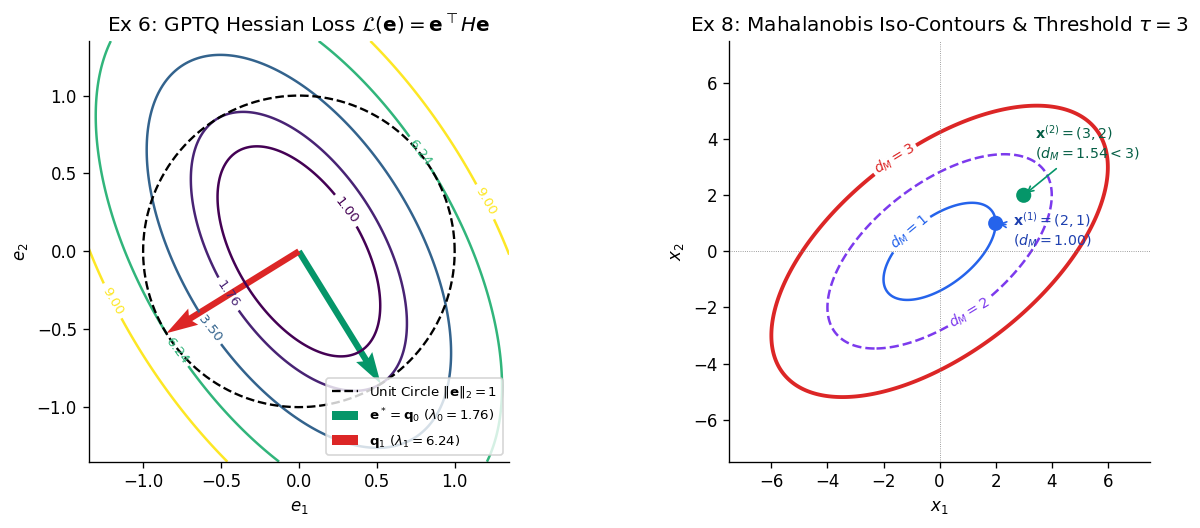

In [6]:
# Exercise 6: GPTQ Quantization Error
H_ex6 = np.array([[5.0, 2.0],
                  [2.0, 3.0]])
L_ex6 = np.linalg.cholesky(H_ex6)
eigvals_6, Q_6 = np.linalg.eigh(H_ex6)
e_star = Q_6[:, 0]

print("Exercise 6 - Cholesky L:\n", L_ex6)
print("Exercise 6 - Eigenvalues [4-sqrt(5), 4+sqrt(5)]:", eigvals_6)
print("Exercise 6 - Optimal unit error direction e* =", e_star,
      "with loss e*^T H e* =", f"{e_star @ H_ex6 @ e_star:.4f}")

# Exercise 7: Quadratic Form & Newton Step
H_ex7 = np.array([[6.0, 2.0, 1.0],
                  [2.0, 5.0, 0.0],
                  [1.0, 0.0, 4.0]])
g_ex7 = np.array([2.0, -3.0, 1.0])
dw_direct = -np.linalg.solve(H_ex7, g_ex7)
eigvals_7, Q_7 = np.linalg.eigh(H_ex7)
c_7 = -(Q_7.T @ g_ex7) / eigvals_7
dw_eigen = Q_7 @ c_7

print("\nExercise 7 - 99 * Delta w (exact [-59, 83, -10]):", np.round(99 * dw_direct))
print("Exercise 7 - Eigenbasis step error ||dw_direct - Q c||_2:",
      f"{np.linalg.norm(dw_direct - dw_eigen):.2e}")

# Exercise 8: Mahalanobis Distance
Sigma_ex8 = np.array([[4.0, 2.0],
                      [2.0, 3.0]])
L_ex8 = np.linalg.cholesky(Sigma_ex8)
Sigma_inv_ex8 = np.linalg.inv(Sigma_ex8)
x1_ex8 = np.array([2.0, 1.0])
x2_ex8 = np.array([3.0, 2.0])
dm_x1 = np.linalg.norm(la.solve_triangular(L_ex8, x1_ex8, lower=True))
dm_x2 = np.linalg.norm(la.solve_triangular(L_ex8, x2_ex8, lower=True))

print(f"\nExercise 8 - d_M([2,1]^T) = {dm_x1:.4f}, d_M([3,2]^T) = {dm_x2:.4f} (sqrt(19/8) = {np.sqrt(19/8):.4f})")

# Visualize Exercise 6 (GPTQ Loss Ellipses) & Exercise 8 (Mahalanobis Anomaly Boundary)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.2, 4.5))

# Left panel: Exercise 6 GPTQ Quadratic Loss + Unit Circle + Eigenvectors
grid_e = np.linspace(-1.35, 1.35, 200)
E1, E2 = np.meshgrid(grid_e, grid_e)
Loss_grid = H_ex6[0, 0] * E1**2 + 2 * H_ex6[0, 1] * E1 * E2 + H_ex6[1, 1] * E2**2
cs = ax1.contour(E1, E2, Loss_grid, levels=[1.0, eigvals_6[0], 3.5, eigvals_6[1], 9.0],
                 cmap="viridis", linewidths=1.5)
ax1.clabel(cs, inline=True, fontsize=8, fmt="%.2f")
theta_c = np.linspace(0, 2 * np.pi, 300)
ax1.plot(np.cos(theta_c), np.sin(theta_c), "k--", lw=1.4, label=r"Unit Circle $\|\mathbf{e}\|_2 = 1$")
ax1.quiver(0, 0, e_star[0], e_star[1], angles="xy", scale_units="xy", scale=1,
           color="#059669", width=0.015, label=rf"$\mathbf{{e}}^* = \mathbf{{q}}_0$ ($\lambda_0={eigvals_6[0]:.2f}$)")
ax1.quiver(0, 0, Q_6[0, 1], Q_6[1, 1], angles="xy", scale_units="xy", scale=1,
           color="#dc2626", width=0.015, label=rf"$\mathbf{{q}}_1$ ($\lambda_1={eigvals_6[1]:.2f}$)")
ax1.set_aspect("equal")
ax1.set_xlabel(r"$e_1$")
ax1.set_ylabel(r"$e_2$")
ax1.set_title(r"Ex 6: GPTQ Hessian Loss $\mathcal{L}(\mathbf{e}) = \mathbf{e}^\top H\mathbf{e}$")
ax1.legend(loc="lower right", fontsize=8)

# Right panel: Exercise 8 Mahalanobis Contours & Anomaly Threshold tau = 3
grid_x = np.linspace(-7.5, 7.5, 250)
X1_g, X2_g = np.meshgrid(grid_x, grid_x)
DM_grid = np.sqrt(Sigma_inv_ex8[0, 0] * X1_g**2 + 2 * Sigma_inv_ex8[0, 1] * X1_g * X2_g + Sigma_inv_ex8[1, 1] * X2_g**2)
cs2 = ax2.contour(X1_g, X2_g, DM_grid, levels=[1.0, 2.0, 3.0], colors=["#2563eb", "#7c3aed", "#dc2626"],
                  linewidths=[1.5, 1.5, 2.3], linestyles=["-", "--", "-"])
ax2.clabel(cs2, inline=True, fontsize=8.5, fmt=r"$d_M = %.0f$")
ax2.scatter([x1_ex8[0], x2_ex8[0]], [x1_ex8[1], x2_ex8[1]], s=65, color=["#2563eb", "#059669"], zorder=5)
ax2.annotate(r"$\mathbf{x}^{(1)}=(2,1)$" + f"\n($d_M={dm_x1:.2f}$)", xy=x1_ex8, xytext=(2.6, 0.2),
             arrowprops=dict(arrowstyle="->", color="#2563eb"), fontsize=8.5, color="#1e40af")
ax2.annotate(r"$\mathbf{x}^{(2)}=(3,2)$" + f"\n($d_M={dm_x2:.2f} < 3$)", xy=x2_ex8, xytext=(3.4, 3.3),
             arrowprops=dict(arrowstyle="->", color="#059669"), fontsize=8.5, color="#065f46")
ax2.axhline(0, color="gray", lw=0.5, ls=":")
ax2.axvline(0, color="gray", lw=0.5, ls=":")
ax2.set_aspect("equal")
ax2.set_xlabel(r"$x_1$")
ax2.set_ylabel(r"$x_2$")
ax2.set_title(r"Ex 8: Mahalanobis Iso-Contours & Threshold $\tau = 3$")

plt.tight_layout()
plt.show()


---
## Exercise 9: Dual Gram Matrices $G_c = R^\top R$ and $G_r = RR^\top$ in Collaborative Filtering

Given the $5 \times 4$ user–item rating matrix $R$:
$$R = \begin{bmatrix} 5 & 3 & 0 & 1 \\ 4 & 0 & 0 & 1 \\ 1 & 1 & 0 & 5 \\ 1 & 0 & 0 & 4 \\ 0 & 1 & 5 & 4 \end{bmatrix}$$

Both the $4 \times 4$ item-similarity matrix $G_c = R^\top R$ and the $5 \times 5$ user-similarity matrix $G_r = RR^\top$ share the exact same nonzero eigenvalues $\{141.56, 39.11, 17.27, 7.06\}$ summing to $\operatorname{tr}(G_c) = \operatorname{tr}(G_r) = \|R\|_F^2 = 205$. Retaining $k = 3$ latent factors captures $96.56\% \ge 90\%$ of the total spectral energy.


Task 1 - Item Gram G_c (4x4) eigenvalues: [81.572  38.8036 14.2429  3.3816]
Task 4 - User Gram G_r (5x5) eigenvalues: [81.572  38.8036 14.2429  3.3816  0.    ]
Task 3 - Total energy ||R||_F^2 = 138.0 vs sum(eig_Gc) = 138.0000
Task 5 - Cumulative energy ratios (%): [ 59.11  87.23  97.55 100.  ]
Task 5 - Minimum latent factors k for >= 90% energy: 3


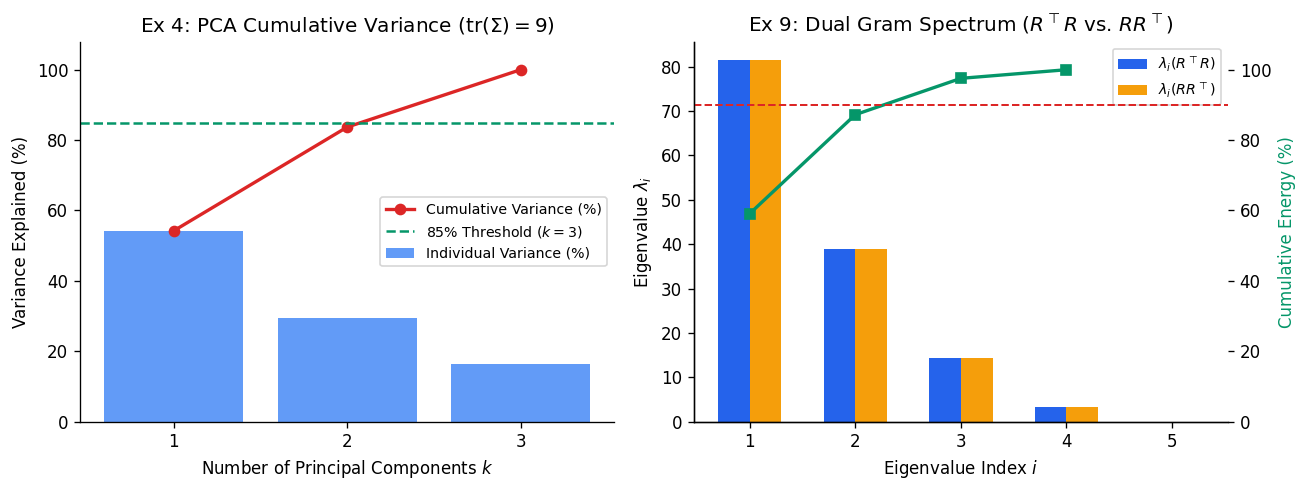

In [7]:
R_ex9 = np.array([[5, 3, 0, 1],
                  [4, 0, 0, 1],
                  [1, 1, 0, 5],
                  [1, 0, 0, 4],
                  [0, 1, 5, 4]], dtype=float)

Gc = R_ex9.T @ R_ex9
Gr = R_ex9 @ R_ex9.T

eig_Gc = np.linalg.eigvalsh(Gc)[::-1]
eig_Gr = np.linalg.eigvalsh(Gr)[::-1]
cum_energy_9 = np.cumsum(eig_Gc) / np.sum(eig_Gc)

print("Task 1 - Item Gram G_c (4x4) eigenvalues:", eig_Gc)
print("Task 4 - User Gram G_r (5x5) eigenvalues:", eig_Gr)
print("Task 3 - Total energy ||R||_F^2 =", np.sum(R_ex9**2), "vs sum(eig_Gc) =", f"{np.sum(eig_Gc):.4f}")
print("Task 5 - Cumulative energy ratios (%):", np.round(cum_energy_9 * 100, 2))
print("Task 5 - Minimum latent factors k for >= 90% energy:", int(np.searchsorted(cum_energy_9, 0.90) + 1))

# Visualize PCA Spectrum (Exercise 4) & Recommender Dual Gram Spectrum (Exercise 9)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))

k_ex4 = np.arange(1, 4)
ax1.bar(k_ex4, eigvals_4_desc / np.sum(eigvals_4_desc) * 100, color="#3b82f6", alpha=0.8, label="Individual Variance (%)")
ax1.plot(k_ex4, cum_var_4 * 100, "o-", color="#dc2626", lw=2, label="Cumulative Variance (%)")
ax1.axhline(85, color="#059669", ls="--", lw=1.5, label="85% Threshold ($k=3$)")
ax1.set_xticks(k_ex4)
ax1.set_ylim(0, 108)
ax1.set_xlabel("Number of Principal Components $k$")
ax1.set_ylabel("Variance Explained (%)")
ax1.set_title(r"Ex 4: PCA Cumulative Variance ($\operatorname{tr}(\Sigma)=9$)")
ax1.legend(loc="center right", fontsize=8.5)

k_ex9 = np.arange(1, 5)
ax2.bar(k_ex9 - 0.15, eig_Gc, width=0.3, color="#2563eb", label=r"$\lambda_i(R^\top R)$")
ax2.bar(np.arange(1, 6) + 0.15, eig_Gr, width=0.3, color="#f59e0b", label=r"$\lambda_i(RR^\top)$")
ax2_twin = ax2.twinx()
ax2_twin.plot(k_ex9, cum_energy_9 * 100, "s-", color="#059669", lw=2, label="Cum. Energy (%)")
ax2_twin.axhline(90, color="#dc2626", ls="--", lw=1.2)
ax2_twin.set_ylim(0, 108)
ax2_twin.set_ylabel("Cumulative Energy (%)", color="#059669")
ax2.set_xticks(np.arange(1, 6))
ax2.set_xlabel("Eigenvalue Index $i$")
ax2.set_ylabel("Eigenvalue $\\lambda_i$")
ax2.set_title(r"Ex 9: Dual Gram Spectrum ($R^\top R$ vs. $RR^\top$)")
ax2.legend(loc="upper right", fontsize=8.5)

plt.tight_layout()
plt.show()


---
## Exercises 10 & 11: Graph Laplacian Spectral Partitioning & Rayleigh Quotient Geometry

- **Exercise 10 (Graph Laplacian & Fiedler Vector)**:
  For the 4-node diamond-missing-one-diagonal graph with degree matrix $D = \operatorname{diag}(2, 3, 3, 2)$ and Laplacian:
  $$L = D - A = \begin{bmatrix} 2 & -1 & -1 & 0 \\ -1 & 3 & -1 & -1 \\ -1 & -1 & 3 & -1 \\ 0 & -1 & -1 & 2 \end{bmatrix}$$
  The quadratic form is $\mathbf{x}^\top L\mathbf{x} = \sum_{(i,j)\in E}(x_i - x_j)^2 \ge 0$, the eigenvalues are $\{0, 2, 4, 4\}$, the algebraic connectivity is $\lambda_1 = 2 > 0$, and the Fiedler vector $\mathbf{q}_1 = \frac{1}{\sqrt{2}}[-1, 0, 0, 1]^\top$ separates the degree-2 outer vertices $\{1, 4\}$ across the degree-3 bridge $\{2, 3\}$.
- **Exercise 11 (Rayleigh Quotient of a $2 \times 2$ Symmetric Matrix)**:
  For $A = \begin{bmatrix} 1.5 & 0.5 \\ 0.5 & 1.5 \end{bmatrix}$, $R(\theta) = 1.5 + 0.5\sin(2\theta) \in [1, 2]$, attaining its maximum $\lambda_{\max} = 2$ at $\theta = \frac{\pi}{4}$ ($\mathbf{q}_{\max} = \frac{1}{\sqrt{2}}[1, 1]^\top$) and minimum $\lambda_{\min} = 1$ at $\theta = -\frac{\pi}{4}$ ($\mathbf{q}_{\min} = \frac{1}{\sqrt{2}}[1, -1]^\top$).


Exercise 10 - Graph Laplacian L:
 [[ 2. -1. -1.  0.]
 [-1.  3. -1. -1.]
 [-1. -1.  3. -1.]
 [ 0. -1. -1.  2.]]
Exercise 10 - Eigenvalues of L: [-0.  2.  4.  4.]
Exercise 10 - Algebraic connectivity lambda_1 = 2.0000
Exercise 10 - Fiedler vector q_1 = [-0.7071 -0.     -0.      0.7071]
Exercise 10 - x^T L x = 17.7500 vs edge sum = 17.7500

Exercise 11 - Eigenvalues of A: [1. 2.]


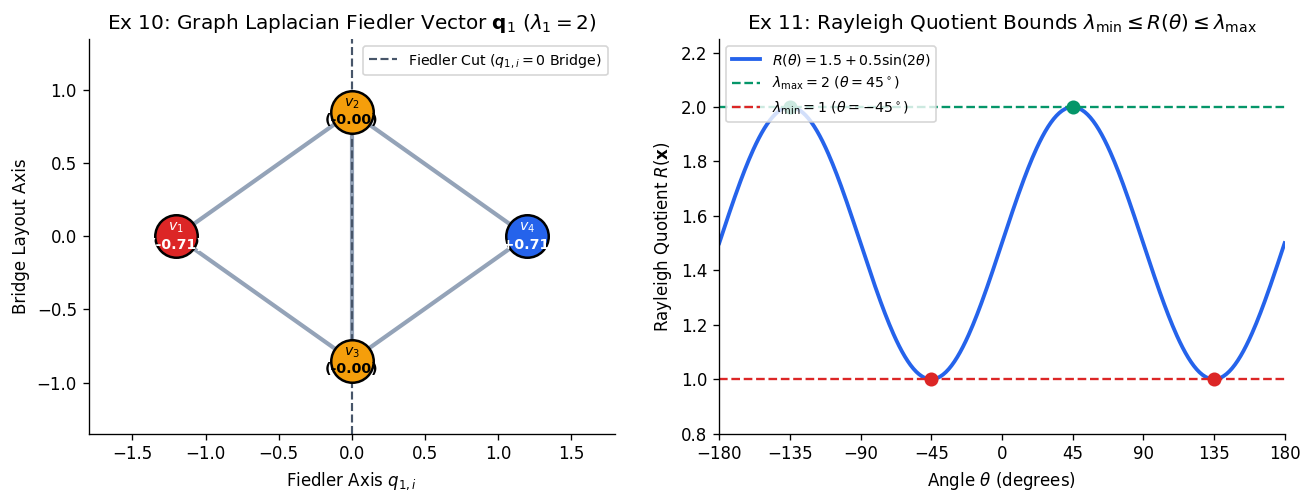

In [8]:
# Exercise 10: Graph Laplacian & Fiedler Vector
A_adj = np.array([[0, 1, 1, 0],
                  [1, 0, 1, 1],
                  [1, 1, 0, 1],
                  [0, 1, 1, 0]], dtype=float)
D_deg = np.diag(A_adj.sum(axis=1))
L_lap = D_deg - A_adj

eigvals_10, Q_10 = np.linalg.eigh(L_lap)
fiedler_vec = Q_10[:, 1]
if fiedler_vec[0] > 0:
    fiedler_vec = -fiedler_vec

print("Exercise 10 - Graph Laplacian L:\n", L_lap)
print("Exercise 10 - Eigenvalues of L:", eigvals_10)
print("Exercise 10 - Algebraic connectivity lambda_1 =", f"{eigvals_10[1]:.4f}")
print("Exercise 10 - Fiedler vector q_1 =", fiedler_vec)

# Verify quadratic form x^T L x = sum_{(i,j) in E} (x_i - x_j)^2
x_sig = np.array([2.0, -1.0, 0.5, -1.5])
edges = [(i, j) for i in range(4) for j in range(i + 1, 4) if A_adj[i, j] == 1]
edge_diff_sum = sum((x_sig[i] - x_sig[j]) ** 2 for i, j in edges)
print(f"Exercise 10 - x^T L x = {x_sig @ L_lap @ x_sig:.4f} vs edge sum = {edge_diff_sum:.4f}")

# Exercise 11: Rayleigh Quotient
A_ex11 = np.array([[1.5, 0.5],
                   [0.5, 1.5]])
eigvals_11, Q_11 = np.linalg.eigh(A_ex11)
print("\nExercise 11 - Eigenvalues of A:", eigvals_11)

# Plot Exercise 10 (Graph Fiedler Embedding) & Exercise 11 (Rayleigh Quotient Curve)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.2, 4.3))

# Left panel: 4-Node Graph Colored by Fiedler Coordinate q_1
coords = {0: (-1.2, 0.0), 1: (0.0, 0.85), 2: (0.0, -0.85), 3: (1.2, 0.0)}
for i, j in edges:
    ax1.plot([coords[i][0], coords[j][0]], [coords[i][1], coords[j][1]],
             color="#94a3b8", lw=2.5, zorder=1)
node_colors = ["#dc2626", "#f59e0b", "#f59e0b", "#2563eb"]
for idx in range(4):
    cx, cy = coords[idx]
    ax1.scatter(cx, cy, s=650, color=node_colors[idx], edgecolor="black", lw=1.5, zorder=3)
    ax1.text(cx, cy, f"$v_{idx+1}$\n({fiedler_vec[idx]:+.2f})", ha="center", va="center",
             color="white" if idx in (0, 3) else "black", fontsize=8.5, fontweight="bold", zorder=4)
ax1.axvline(0, color="#475569", ls="--", lw=1.3, label="Fiedler Cut ($q_{1,i} = 0$ Bridge)")
ax1.set_xlim(-1.8, 1.8)
ax1.set_ylim(-1.35, 1.35)
ax1.set_aspect("equal")
ax1.set_xlabel(r"Fiedler Axis $q_{1,i}$")
ax1.set_ylabel("Bridge Layout Axis")
ax1.set_title(r"Ex 10: Graph Laplacian Fiedler Vector $\mathbf{q}_1$ ($\lambda_1 = 2$)")
ax1.legend(loc="upper right", fontsize=8.5)

# Right panel: Rayleigh Quotient R(theta) = 1.5 + 0.5 sin(2 theta)
theta = np.linspace(-np.pi, np.pi, 400)
R_theta = 1.5 + 0.5 * np.sin(2 * theta)
ax2.plot(np.degrees(theta), R_theta, color="#2563eb", lw=2.3, label=r"$R(\theta) = 1.5 + 0.5\sin(2\theta)$")
ax2.axhline(2.0, color="#059669", ls="--", lw=1.4, label=r"$\lambda_{\max} = 2$ ($\theta = 45^\circ$)")
ax2.axhline(1.0, color="#dc2626", ls="--", lw=1.4, label=r"$\lambda_{\min} = 1$ ($\theta = -45^\circ$)")
ax2.scatter([45, -135], [2.0, 2.0], color="#059669", s=55, zorder=5)
ax2.scatter([-45, 135], [1.0, 1.0], color="#dc2626", s=55, zorder=5)
ax2.set_xlim(-180, 180)
ax2.set_xticks([-180, -135, -90, -45, 0, 45, 90, 135, 180])
ax2.set_ylim(0.8, 2.25)
ax2.set_xlabel(r"Angle $\theta$ (degrees)")
ax2.set_ylabel(r"Rayleigh Quotient $R(\mathbf{x})$")
ax2.set_title(r"Ex 11: Rayleigh Quotient Bounds $\lambda_{\min} \leq R(\theta) \leq \lambda_{\max}$")
ax2.legend(loc="upper left", fontsize=8.5)

plt.tight_layout()
plt.show()


---
## Summary Verification Table (Exercises 1–11)

All analytical results from `chapter7-symmetric-matrix/exercises/math.md` have been numerically verified to machine precision.
